# Can machine learning split Pakistan into 5 social classes?

**Data:** HIES 2024-25, Section 6A (household consumption expenditure), with `weight.dta`.

**Question:** If we group households by how much they spend, how many people fall in each of 5 classes (lower to upper)?

**Rule:** every number about *the population* uses the survey weight. Without it, the results describe the 30,123 sampled households, not Pakistan.

### KNN or K-means?

| | K-means | KNN (k-nearest neighbours) |
|---|---|---|
| Type | **Unsupervised**: finds groups by itself | **Supervised**: needs groups that already exist |
| Input | Data only | Data **plus a label** for each row |
| Output | 5 groups (clusters) | Predicts the label of a new row |
| Use here | **Create** the 5 classes | **Check** whether the classes can be recognised from spending patterns |

KNN cannot divide society into classes on its own, because it has no labels to learn from. So this notebook:

1. builds each household's monthly spending per person from Section 6A;
2. makes the standard benchmark: **quintiles** (5 groups of exactly 20% of people each);
3. **Test A:** weighted K-means on spending per person, to see where the natural class boundaries fall;
4. **Test B:** weighted K-means on the *pattern* of spending (12 categories);
5. **KNN:** learns Test A's classes from the spending pattern;
6. shows what happens if you **forget the weight**.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, adjusted_rand_score

DATA = "../../HIES 2024_2025/Stata data/"
OUT = "outputs/"
os.makedirs(OUT, exist_ok=True)

CLASS_NAMES = {1: "Lower", 2: "Lower-middle", 3: "Middle", 4: "Upper-middle", 5: "Upper"}
CLASS_COLORS = ["#eda100", "#1baf7a", "#eb6834", "#2a78d6", "#e34948"]   # 5 clearly different colours (colour-blind checked)
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # categorical slots 1-3 (blue, orange, aqua)
SURFACE = "#fcfcfb"
NAMES = [CLASS_NAMES[k] for k in range(1, 6)]
XPOS = np.arange(5)

def style(ax, ylabel):
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})
pd.set_option("display.float_format", "{:,.1f}".format)

def read(name, **kw):
    return pd.read_stata(DATA + name, convert_categoricals=False, **kw)

def wmean(x, w):
    return float(np.average(x, weights=w))


## Step 1: Monthly spending for each household

Section 6A has one row per household per item, about 285 items. For each item we add the four sources of consumption:
`v1` bought + `v2` received as wages in kind + `v3` own production + `v4` gifts/assistance.

Items were asked over different time periods, so everything is converted to **one month**:

| Part | Items | Asked for | To get a monthly value |
|---|---|---|---|
| A | Perishable food (milk, meat, fruit, vegetables, sugar, drinks) | last 14 days | × 365 / 12 / 14 |
| B | Staple food, prepared food, cleaning, personal care | last month | × 1 |
| C | Tobacco, water, electricity, gas, fuel | last month | × 1 |
| D | Clothing, rent, health, education, transport, etc. | last 12 months | ÷ 12 |
| E | Durable goods (furniture, appliances, vehicles, gold) | last 12 months | ÷ 12 |

The part of each item comes from the questionnaire pages. Total rows (`itc` below 10000) are dropped so nothing is counted twice.


In [2]:
raw = read("sec_6a_consum_exp.dta", columns=["hhcode", "prcode", "itc", "v1", "v2", "v3", "v4"])
raw["value"] = raw[["v1", "v2", "v3", "v4"]].fillna(0).sum(axis=1)

def part_of(code):
    group = code // 100
    if group in (112, 113, 114, 116, 117, 122) or 11801 <= code <= 11810 or 11901 <= code <= 11908:
        return "A"
    if group in (111, 115, 121, 561, 1211, 1212, 1213) or 11909 <= code <= 11912 or 110000 <= code < 111000:
        return "B"
    if code // 1000 in (22, 45) or group in (441, 442):
        return "C"
    if (code // 1000 == 51 or group in (522, 911) or 53103 <= code <= 53107 or 54104 <= code <= 54107
            or code in (55101, 55201, 71101, 82101, 123102, 123103)):
        return "E"
    return "D"

items = raw[(raw.itc >= 10000) & (raw.value > 0)].copy()
items["part"] = items.itc.map({c: part_of(c) for c in items.itc.unique()})
PER_MONTH = {"A": 365 / 12 / 14, "B": 1, "C": 1, "D": 1 / 12, "E": 1 / 12}
items["monthly"] = items.value * items.part.map(PER_MONTH)

# Check: our item sums per part vs. the totals recorded in the questionnaire (codes 1000-6000)
totals = raw[raw.itc.isin([1000, 2000, 4000, 5000, 6000])].pivot_table(index="hhcode", columns="itc", values="value")
ours = items.pivot_table(index="hhcode", columns="part", values="value", aggfunc="sum").fillna(0)
check = {}
for p, t in zip("ABCDE", [1000, 2000, 4000, 5000, 6000]):
    both = totals[[t]].join(ours[[p]], how="inner").dropna()
    check[p] = ((both[t] - both[p]).abs() <= 0.01 * both[t] + 2).mean() * 100
print("Households where our part total matches the recorded total (within 1%):")
print({k: f"{v:.0f}%" for k, v in check.items()})


Households where our part total matches the recorded total (within 1%):
{'A': '100%', 'B': '100%', 'C': '100%', 'D': '82%', 'E': '100%'}


Parts A, B, C and E match the recorded totals for 100% of households, so the part assignment is right.
Part D matches about 82%. Its recorded total disagrees with its own items, mostly in households that pay house rent, while the item values themselves look plausible (median urban rent about Rs 120,000 a year). We use the items, which are the original answers.


## Step 2: Spending per person, and the right weight

A household of 10 spending Rs 80,000 is poorer than a household of 2 spending Rs 50,000, so we divide by household size.

**Which weight?** `weight.dta` gives each household's weight, meaning how many households it represents. We want shares of **people**, so each household counts as **weight × household size** people. This is the `people_w` column below.


In [3]:
COICOP = {1: "Food", 2: "Tobacco", 3: "Clothing", 4: "Housing & utilities", 5: "Furnishings",
          6: "Health", 7: "Transport", 8: "Communication", 9: "Recreation", 10: "Education",
          11: "Restaurants & hotels", 12: "Personal care & misc."}
items["division"] = items.itc // 10000

hh = items.pivot_table(index="hhcode", columns="division", values="monthly", aggfunc="sum").fillna(0)
hh.columns = [COICOP[c] for c in hh.columns]
CATS = list(hh.columns)
hh = hh.reset_index()

roster = read("plist_roster.dta", columns=["hhcode", "s1aq10"])
size = roster[roster.s1aq10 == 1].groupby("hhcode").size().rename("hhsize")
info = read("section_info.dta", columns=["hhcode", "prcode", "province", "region"])
weight = read("weight.dta")

hh = hh.merge(size, on="hhcode").merge(info, on="hhcode").merge(weight, on="prcode")
hh["hhcode"] = hh.hhcode.astype("int64")
hh["monthly_total"] = hh[CATS].sum(axis=1)
hh["per_person"] = hh.monthly_total / hh.hhsize
hh["people_w"] = hh.weight * hh.hhsize

print(f"Households: {len(hh):,}   People represented: {hh.people_w.sum() / 1e6:,.1f} million")
print(f"Average monthly household spending: Rs {wmean(hh.monthly_total, hh.weight):,.0f}")
print(f"Average monthly spending per person: Rs {wmean(hh.per_person, hh.people_w):,.0f}")


Households: 30,123   People represented: 239.8 million
Average monthly household spending: Rs 81,351
Average monthly spending per person: Rs 13,608


## Step 3: Benchmark, weighted quintiles

This is what PBS does. Rank all **people** by spending per person and cut them into 5 groups of **20% of the population** each. Because the cut is made on weighted people, each quintile holds 20% of Pakistan's people, not 20% of the sample.


In [4]:
order = hh.sort_values("per_person")
cum_share = order.people_w.cumsum() / order.people_w.sum()
hh.loc[order.index, "quintile"] = np.minimum(np.ceil(cum_share * 5), 5).astype(int)
hh["quintile"] = hh.quintile.astype(int)

def summary(col):
    g = hh.groupby(col)
    return pd.DataFrame({
        "class": [CLASS_NAMES[k] for k in g.groups],
        "% of people": g.people_w.sum() / hh.people_w.sum() * 100,
        "% of households": g.weight.sum() / hh.weight.sum() * 100,
        "sample households": g.size(),
        "Rs/person/month from": g.per_person.min().round(0),
        "to": g.per_person.max().round(0),
        "average Rs/person/month": g.apply(lambda d: wmean(d.per_person, d.people_w), include_groups=False).round(0),
    })

quintiles = summary("quintile")
quintiles


,class,% of people,% of households,sample households,Rs/person/month from,to,average Rs/person/month
quintile,,,,,,,
1,Lower,20.0,15.7,5462,"1,991.0","6,809.0","5,381.0"
2,Lower-middle,20.0,17.6,5618,"6,809.0","9,032.0","7,902.0"
3,Middle,20.0,19.4,5870,"9,033.0","11,937.0","10,402.0"
4,Upper-middle,20.0,21.6,6233,"11,937.0","17,237.0","14,206.0"
5,Upper,20.0,25.6,6940,"17,237.0","501,810.0","30,143.0"


## Step 4: Test A, weighted K-means on spending per person

K-means looks for 5 groups where households inside each group spend as similarly as possible.

- We use the **logarithm** of spending per person. Money is skewed, and a few very rich households would otherwise get a group of their own. In logs, "twice as much" is the same distance everywhere.
- `sample_weight=people_w` makes K-means treat each household as the number of people it represents. **This is where the weight goes into the algorithm.**
- Unlike quintiles, the groups do **not** have to be 20% each. That is what we want to find out.


In [5]:
X_level = np.log(hh[["per_person"]].to_numpy())

def kmeans_classes(X, sample_weight, seed=42):
    km = KMeans(n_clusters=5, n_init=20, random_state=seed).fit(X, sample_weight=sample_weight)
    rank = np.argsort(np.argsort(km.cluster_centers_[:, 0]))   # cluster with lowest centre -> class 1
    return rank[km.labels_] + 1

hh["class_A"] = kmeans_classes(X_level, hh.people_w)
test_a = summary("class_A")
test_a


,class,% of people,% of households,sample households,Rs/person/month from,to,average Rs/person/month
class_A,,,,,,,
1,Lower,16.9,13.1,4608,"1,991.0","6,440.0","5,152.0"
2,Lower-middle,32.6,29.2,9214,"6,440.0","10,287.0","8,285.0"
3,Middle,29.7,31.0,9075,"10,288.0","16,882.0","13,016.0"
4,Upper-middle,16.8,20.8,5718,"16,885.0","34,370.0","22,496.0"
5,Upper,4.0,5.9,1508,"34,408.0","501,810.0","59,203.0"


In [6]:
# Stability: does a different random start give the same classes?
for seed in [1, 2, 3]:
    other = kmeans_classes(X_level, hh.people_w, seed=seed)
    print(f"seed {seed}: agreement with seed 42 (adjusted Rand index) = {adjusted_rand_score(hh.class_A, other):.3f}")


seed 1: agreement with seed 42 (adjusted Rand index) = 0.963


seed 2: agreement with seed 42 (adjusted Rand index) = 0.983


seed 3: agreement with seed 42 (adjusted Rand index) = 0.995


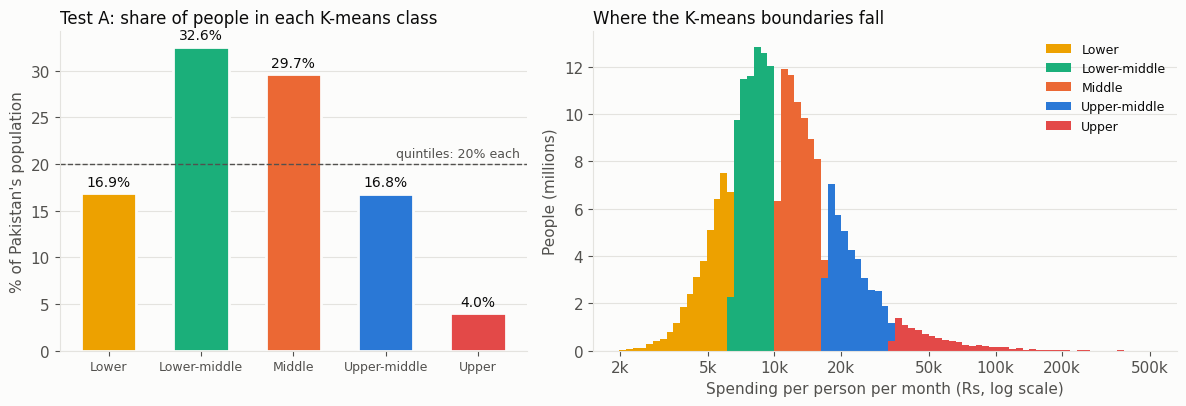

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
share = test_a["% of people"].to_numpy()
bars = ax.bar(test_a["class"], share, color=CLASS_COLORS, width=0.6, edgecolor="#fcfcfb", linewidth=2)
ax.axhline(20, color=INK_2, lw=1, ls="--")
ax.text(4.45, 20.8, "quintiles: 20% each", ha="right", color=INK_2, fontsize=9)
for b, v in zip(bars, share):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", color=INK, fontsize=10)
ax.set_ylabel("% of Pakistan's population")
ax.set_title("Test A: share of people in each K-means class", loc="left", fontsize=12)
ax.tick_params(axis="x", labelsize=9)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)

ax = axes[1]
bins = np.logspace(np.log10(hh.per_person.min()), np.log10(hh.per_person.max()), 80)
for k in range(1, 6):
    d = hh[hh.class_A == k]
    ax.hist(d.per_person, bins=bins, weights=d.people_w / 1e6, color=CLASS_COLORS[k - 1], label=CLASS_NAMES[k])
ax.set_xscale("log")
ticks = [2000, 5000, 10000, 20000, 50000, 100000, 200000, 500000]
ax.set_xticks(ticks, [f"{t // 1000}k" for t in ticks]); ax.minorticks_off()
ax.set_xlabel("Spending per person per month (Rs, log scale)")
ax.set_ylabel("People (millions)")
ax.set_title("Where the K-means boundaries fall", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(OUT + "test_a_classes.png", dpi=150)
plt.show()


## What if we forget the weight?

Same K-means, but every sampled household counts once, and the shares are counted over the sample. This is the mistake the weight protects against.


In [8]:
hh["class_A_unweighted"] = kmeans_classes(X_level, None)
compare = pd.DataFrame({
    "class": [CLASS_NAMES[k] for k in range(1, 6)],
    "% of people (weighted, correct)": test_a["% of people"].to_numpy(),
    "% of sample (no weight)": hh.class_A_unweighted.value_counts(normalize=True).sort_index().to_numpy() * 100,
})
# Province mix of the sample vs. the population
prov = hh.groupby("province").agg(sample=("hhcode", "size"), people=("people_w", "sum"))
prov.index = prov.index.map({1: "KP", 2: "Punjab + ICT", 3: "Sindh", 4: "Balochistan"})
prov = (prov / prov.sum() * 100).rename(columns={"sample": "% of sample households", "people": "% of population"})
display(compare)
display(prov)


,class,"% of people (weighted, correct)",% of sample (no weight)
0,Lower,16.9,16.3
1,Lower-middle,32.6,31.4
2,Middle,29.7,29.6
3,Upper-middle,16.8,18.0
4,Upper,4.0,4.8


,% of sample households,% of population
province,,
KP,18.6,16.9
Punjab + ICT,44.8,53.8
Sindh,27.6,23.1
Balochistan,9.0,6.1


## Step 5: Test B, weighted K-means on the *pattern* of spending

Instead of one number, each household is described by **12 numbers**: spending per person on food, tobacco, clothing, housing, furnishings, health, transport, communication, recreation, education, restaurants, and personal care.

These are on a log scale (`log(1 + Rs)`, so a zero stays zero) and standardised with weighted means, so no category dominates just because it costs more.

**Theory:** if classes are real "ways of living", K-means should find them in this pattern.


In [9]:
pattern = np.log1p(hh[CATS].div(hh.hhsize, axis=0))
mu = np.average(pattern, axis=0, weights=hh.people_w)
sd = np.sqrt(np.average((pattern - mu) ** 2, axis=0, weights=hh.people_w))
Z = ((pattern - mu) / sd).to_numpy()

km_b = KMeans(n_clusters=5, n_init=20, random_state=42).fit(Z, sample_weight=hh.people_w)
# Number clusters from poorest to richest by average spending per person
avg = pd.Series({c: wmean(hh.per_person[km_b.labels_ == c], hh.people_w[km_b.labels_ == c]) for c in range(5)})
hh["class_B"] = pd.Series(km_b.labels_).map({c: r + 1 for r, c in enumerate(avg.sort_values().index)}).to_numpy()
test_b = summary("class_B")
display(test_b)

# How do Test B clusters line up with quintiles?  (row = cluster, % of its people in each quintile)
cross = pd.crosstab(hh.class_B, hh.quintile, values=hh.people_w, aggfunc="sum", normalize="index") * 100
cross.index = [f"Cluster {k}" for k in cross.index]; cross.columns = [f"Q{c}" for c in cross.columns]
display(cross.round(0))

# What makes each cluster different? Share of its people with ZERO spending on a category
zero = pd.DataFrame({cat: hh.groupby("class_B").apply(
    lambda d: (d.people_w * (d[cat] == 0)).sum() / d.people_w.sum() * 100, include_groups=False)
    for cat in ["Tobacco", "Education", "Recreation", "Restaurants & hotels"]})
zero.index = [f"Cluster {k}" for k in zero.index]
display(zero.round(0).add_suffix(" = 0 (% of people)"))


,class,% of people,% of households,sample households,Rs/person/month from,to,average Rs/person/month
class_B,,,,,,,
1,Lower,23.3,20.7,7056,"1,991.0","87,906.0","6,412.0"
2,Lower-middle,20.3,17.1,5260,"4,151.0","68,780.0","10,760.0"
3,Middle,25.1,23.2,6774,"4,292.0","203,141.0","10,818.0"
4,Upper-middle,14.3,19.4,5750,"5,637.0","395,070.0","14,895.0"
5,Upper,17.0,19.5,5283,"12,630.0","501,810.0","29,884.0"


,Q1,Q2,Q3,Q4,Q5
Cluster 1,68.0,23.0,6.0,2.0,1.0
Cluster 2,10.0,28.0,31.0,27.0,5.0
Cluster 3,8.0,27.0,34.0,27.0,4.0
Cluster 4,1.0,15.0,27.0,33.0,24.0
Cluster 5,0.0,0.0,0.0,15.0,85.0


,Tobacco = 0 (% of people),Education = 0 (% of people),Recreation = 0 (% of people),Restaurants & hotels = 0 (% of people)
Cluster 1,57.0,70.0,42.0,31.0
Cluster 2,0.0,29.0,0.0,18.0
Cluster 3,98.0,18.0,0.0,23.0
Cluster 4,56.0,97.0,89.0,21.0
Cluster 5,67.0,18.0,3.0,4.0


## Step 6: KNN, can the class be recognised from the spending pattern?

Now that Test A has given every household a class label, KNN has something to learn.

- **Features:** the 12-category spending pattern (`Z` from Test B).
- **Label:** the Test A class.
- 75% of households train the model and 25% are held back to test it.
- Accuracy is **weighted**, so it measures how often the class is right for *people in Pakistan*.

High accuracy means the classes are not just arbitrary cuts of one number: households in the same class really do spend in similar ways.


In [10]:
X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(
    Z, hh.class_A, hh.people_w, test_size=0.25, random_state=42, stratify=hh.class_A)

results = {}
for k in [5, 15, 25, 51]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    results[k] = accuracy_score(y_te, knn.predict(X_te), sample_weight=w_te) * 100
print("Weighted accuracy on held-out households:", {k: f"{v:.1f}%" for k, v in results.items()})

best_k = max(results, key=results.get)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr, y_tr)
pred = knn.predict(X_te)
conf = pd.crosstab(pd.Series(y_te.to_numpy(), name="true class"), pd.Series(pred, name="predicted"),
                   values=w_te.to_numpy(), aggfunc="sum", normalize="index") * 100
conf.index = [CLASS_NAMES[k] for k in conf.index]; conf.columns = [CLASS_NAMES[k] for k in conf.columns]
print(f"\nk = {best_k}. Rows: true class; values: % of that class's people predicted as each class")
conf.round(0)


Weighted accuracy on held-out households: {5: '83.7%', 15: '84.5%', 25: '84.3%', 51: '83.5%'}



k = 15. Rows: true class; values: % of that class's people predicted as each class


,Lower,Lower-middle,Middle,Upper-middle,Upper
Lower,87.0,13.0,0.0,0.0,0.0
Lower-middle,4.0,93.0,3.0,0.0,0.0
Middle,0.0,15.0,83.0,1.0,0.0
Upper-middle,0.0,0.0,27.0,73.0,0.0
Upper,0.0,0.0,1.0,35.0,63.0


## Step 7: Adding income from Section 1B

`sec_1b_emp_income` has one row per person aged 10+, with what each person **earned**. The CSV copy, `CSV data/sec_1b_emp_income.csv`, holds the same numbers; we read the Stata file to stay consistent with the rest of the notebook.

| Column | Meaning | How we use it |
|---|---|---|
| `s1bq06` | Cash earned last month (main job) | × months worked (`s1bq07`) if there is no yearly figure |
| `s1bq08` | Cash earned last year (main job) | used first, when reported |
| `s1bq10` | Second job, last year | added |
| `s1bq11` | Other jobs, last year | added |
| `s1bq12` | Payment in kind that was sold | added |
| `s1bq13` | Pension and benefits, last year | added |

Household income = everyone's yearly total ÷ 12.

**Important:** this is income from **jobs and pensions only**. It does **not** include business profits (Section 11), farm income (Section 10), remittances or BISP (Section 8), or the value of living in your own house. So it is lower than the household's true income, and lower than its spending.

**The key point: Rs 34,400 is not a salary.** The class boundaries are spending **per person**. A household's earnings are shared by everyone living in it:

> One earner on Rs 40,000 supporting a family of 6 → Rs 40,000 ÷ 6 = **Rs 6,700 per person** → *lower-middle* class.
> To be *upper* class, a family of 6 must spend more than 6 × 34,400 = **Rs 206,000 a month**.


In [11]:
emp = read("sec_1b_emp_income.dta")
emp["hhcode"] = emp.hhcode.round().astype("int64")
pos = lambda col: emp[col].fillna(0).clip(lower=0)

months_worked = emp.s1bq07.fillna(12).clip(1, 12)
main_job_year = np.where(pos("s1bq08") > 0, pos("s1bq08"), pos("s1bq06") * months_worked)
emp["income_year"] = main_job_year + pos("s1bq10") + pos("s1bq11") + pos("s1bq12") + pos("s1bq13")
emp["is_earner"] = emp.income_year > 0
# One worker's monthly pay from the main job (for the "salary" comparison)
emp["main_job_month"] = np.where(pos("s1bq06") > 0, emp.s1bq06, np.where(pos("s1bq08") > 0, emp.s1bq08 / 12, np.nan))

income = emp.groupby("hhcode").agg(income_month=("income_year", lambda s: s.sum() / 12),
                                   earners=("is_earner", "sum")).reset_index()
hh = hh.drop(columns=["income_month", "earners"], errors="ignore").merge(income, on="hhcode", how="left")
hh[["income_month", "earners"]] = hh[["income_month", "earners"]].fillna(0)
hh["income_per_person"] = hh.income_month / hh.hhsize

def wmedian(x, w):
    x, w = np.asarray(x, float), np.asarray(w, float)
    o = np.argsort(x); cw = np.cumsum(w[o])
    return x[o][np.searchsorted(cw, cw[-1] / 2)]

profile = pd.DataFrame({
    CLASS_NAMES[k]: {
        "people per household": wmean(g.hhsize, g.weight),
        "earners per household": wmean(g.earners, g.weight),
        "household spending / month (median Rs)": wmedian(g.monthly_total, g.weight),
        "household job income / month (median Rs)": wmedian(g.income_month, g.weight),
        "spending per person (median Rs)": wmedian(g.per_person, g.people_w),
        "job income per person (median Rs)": wmedian(g.income_per_person, g.people_w),
    } for k, g in hh.groupby("class_A")})
profile.round(1)


,Lower,Lower-middle,Middle,Upper-middle,Upper
people per household,7.7,6.7,5.7,4.8,4.1
earners per household,1.9,1.7,1.5,1.3,1.2
household spending / month (median Rs),"36,654.9","51,042.1","67,360.3","99,876.2","196,784.5"
household job income / month (median Rs),"26,833.3","35,333.3","45,000.0","62,000.0","100,000.0"
spending per person (median Rs),"5,331.9","8,250.7","12,761.5","21,293.6","47,104.7"
job income per person (median Rs),"3,805.6","5,937.5","8,928.6","14,583.3","28,888.9"


In [12]:
# What does one WORKER earn from their main job, in each class?
workers = emp[emp.main_job_month > 0].merge(hh[["hhcode", "class_A", "weight"]], on="hhcode")
pay = pd.Series({CLASS_NAMES[k]: wmedian(g.main_job_month, g.weight) for k, g in workers.groupby("class_A")},
                name="median monthly pay of one worker (Rs)")
display(pay.to_frame())
share_40k = (workers.weight * (workers.main_job_month >= 40000)).sum() / workers.weight.sum() * 100
print(f"All workers: median pay Rs {wmedian(workers.main_job_month, workers.weight):,.0f}; "
      f"{share_40k:.0f}% earn Rs 40,000 or more a month")

both = hh[hh.income_per_person > 0]
r = np.corrcoef(np.log(both.per_person), np.log(both.income_per_person))[0, 1]
print(f"Correlation between spending per person and job income per person (logs): {r:.2f}")


,median monthly pay of one worker (Rs)
Lower,"15,000.0"
Lower-middle,"21,500.0"
Middle,"30,000.0"
Upper-middle,"45,000.0"
Upper,"80,000.0"


All workers: median pay Rs 25,000; 28% earn Rs 40,000 or more a month
Correlation between spending per person and job income per person (logs): 0.71


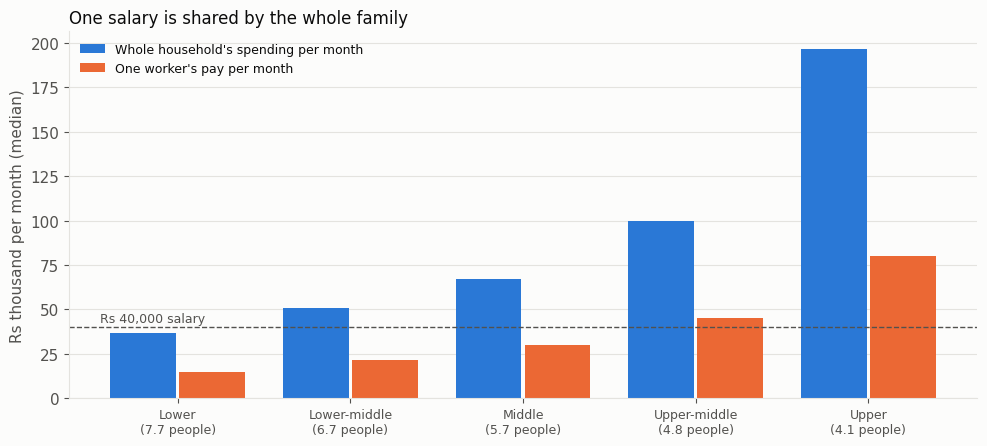

In [13]:
# Chart: why a Rs 40,000 salary is not "upper class"
fig, ax = plt.subplots(figsize=(10, 4.6))
bw = 0.38
spend = profile.loc["household spending / month (median Rs)"].to_numpy() / 1000
ax.bar(XPOS - bw / 2 - 0.01, spend, bw, color=SERIES[0], label="Whole household's spending per month")
ax.bar(XPOS + bw / 2 + 0.01, pay.to_numpy() / 1000, bw, color=SERIES[1], label="One worker's pay per month")
ax.axhline(40, color=INK_2, lw=1, ls="--")
ax.text(-0.45, 43, "Rs 40,000 salary", ha="left", color=INK_2, fontsize=9)
people = profile.loc["people per household"].to_numpy()
ax.set_xticks(XPOS, [f"{n}\n({p:.1f} people)" for n, p in zip(NAMES, people)], fontsize=9)
style(ax, "Rs thousand per month (median)")
ax.set_title("One salary is shared by the whole family", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.savefig(OUT + "household_vs_salary.png", dpi=150); plt.show()


## Step 8: Full income (business, farm, transfers, property), and classes based on income

**Business and farm income are already inside Section 1B.** The questionnaire's own *Balance sheet for income* (male questionnaire, page 30) defines household income as the Section 1B columns. For employers, shopkeepers and farmers, the "main job" amount *is* their net business or farm income. Sections 10 and 11 are the detailed accounts behind that number. The check below confirms it, so adding Sections 10/11 again would **count the same money twice**.

What Section 1B does **not** include, and we add now (all asked "during the last 1 year", so ÷ 12):

| Source | File and codes |
|---|---|
| Remittances from within Pakistan | `sec_8a` code 802 |
| Remittances from abroad | `sec_8a` codes 805-808 (by bank, hundi, mobile, other). Code 804 is only yes/no. |
| BISP / Ehsaas and other government aid | `sec_8a` codes 820, 821 |
| Zakat and help from public or private sources | `sec_8a` codes 812, 813. Code 811 is only yes/no. |
| Boarders' rent, gifts received and sold | `sec_8a` codes 817, 819 |
| Rent received from land, buildings, business property, farm equipment | `sec_9a` Q4, `sec_11` codes 288-289, `sec_10a` code 197 |
| Profit on savings, dividends, interest on loans given | `sec_9b` codes 953, 960, 970 |

**Not income** (left out): selling assets or gold, loans taken, savings withdrawn, committees, inheritance and dowry, and one-off insurance claims.


In [14]:
# Check: a self-employed person's Section 11 profit vs. what they reported in Section 1B
biz = read("sec_11ab_nonagri.dta")
biz["hhcode"] = biz.hhcode.round().astype("int64")
biz["s11c"] = biz.s11c.fillna(0)
key = ["hhcode", "idc", "sheetno"]
amount = lambda codes: biz[biz.code.isin(codes)].groupby(key).s11c.sum()
revenue = amount(range(251, 260)).add(amount(range(266, 279)), fill_value=0)
costs = amount(range(201, 212)).add(amount(range(221, 230)), fill_value=0).add(amount(range(241, 246)), fill_value=0)
profit = revenue.sub(costs, fill_value=0).rename("sheet_profit").reset_index().groupby(["hhcode", "idc"]).sheet_profit.sum()

self_emp = emp[emp.s1bq02.isin([1, 2, 3])].set_index(["hhcode", "idc"])
both = self_emp.join(profit, how="inner")
both = both[both.income_year > 0]
ratio = both.sheet_profit / (both.income_year - pos("s1bq13").reindex(both.index, fill_value=0))
print(f"{len(both):,} self-employed people have a business sheet.")
print(f"Sheet profit ÷ Section 1B earnings: median {ratio.median():.2f}; "
      f"within ±25% for {((ratio - 1).abs() <= 0.25).mean() * 100:.0f}% of them")


6,425 self-employed people have a business sheet.
Sheet profit ÷ Section 1B earnings: median 1.02; within ±25% for 71% of them


In [15]:
def yearly_by_hh(df, codes, col):
    d = df[df.code.isin(codes)].copy()
    d["hhcode"] = d.hhcode.round().astype("int64")
    return d.groupby("hhcode")[col].sum()

transfers_8a = read("sec_8a.dta")
prop_9a, fin_9b, agri_10a = read("sec_9a.dta"), read("sec_9b.dta"), read("sec_10a_agrisheet.dta")

SOURCES = {
    "remittances (Pakistan)": yearly_by_hh(transfers_8a, [802], "c02"),
    "remittances (abroad)": yearly_by_hh(transfers_8a, [805, 806, 807, 808], "c02"),
    "BISP & govt aid": yearly_by_hh(transfers_8a, [820, 821], "c02"),
    "zakat & help": yearly_by_hh(transfers_8a, [812, 813], "c02"),
    "boarders & gifts sold": yearly_by_hh(transfers_8a, [817, 819], "c02"),
    "rent received": yearly_by_hh(prop_9a, [901, 902, 903, 904], "s9aq04")
        .add(yearly_by_hh(biz, [288, 289], "s11a"), fill_value=0)
        .add(yearly_by_hh(agri_10a, [197], "s10c1"), fill_value=0),
    "profit & dividends": yearly_by_hh(fin_9b, [953, 960, 970], "c02"),
}
extra = (pd.DataFrame(SOURCES).reindex(hh.hhcode).fillna(0).clip(lower=0) / 12).reset_index(drop=True)
TRANSFER_COLS = list(SOURCES)[:5]
hh = hh.drop(columns=list(SOURCES), errors="ignore")
hh = pd.concat([hh.reset_index(drop=True), extra], axis=1)
hh["transfers"] = hh[TRANSFER_COLS].sum(axis=1)
hh["property_income"] = hh[["rent received", "profit & dividends"]].sum(axis=1)
hh["full_income"] = hh.income_month + hh.transfers + hh.property_income
hh["full_income_pp"] = hh.full_income / hh.hhsize

by_class = pd.DataFrame({
    CLASS_NAMES[k]: {
        "jobs, business & farm (Rs)": wmean(g.income_month, g.weight),
        "transfers (Rs)": wmean(g.transfers, g.weight),
        "property income (Rs)": wmean(g.property_income, g.weight),
        "FULL income (Rs)": wmean(g.full_income, g.weight),
        "spending (Rs)": wmean(g.monthly_total, g.weight),
        "% of households getting remittances from abroad": (g.weight * (g["remittances (abroad)"] > 0)).sum() / g.weight.sum() * 100,
        "% of households getting BISP / govt aid": (g.weight * (g["BISP & govt aid"] > 0)).sum() / g.weight.sum() * 100,
    } for k, g in hh.groupby("class_A")})
print("Average per household per month, by spending class (weighted):")
by_class.round(0)


Average per household per month, by spending class (weighted):


,Lower,Lower-middle,Middle,Upper-middle,Upper
"jobs, business & farm (Rs)","30,596.0","39,976.0","51,683.0","75,998.0","148,807.0"
transfers (Rs),"3,792.0","6,020.0","10,015.0","17,199.0","32,704.0"
property income (Rs),326.0,680.0,"1,410.0","3,097.0","8,854.0"
FULL income (Rs),"34,714.0","46,677.0","63,109.0","96,294.0","190,365.0"
spending (Rs),"39,571.0","55,277.0","74,438.0","109,062.0","242,304.0"
% of households getting remittances from abroad,2.0,5.0,10.0,16.0,18.0
% of households getting BISP / govt aid,43.0,31.0,17.0,7.0,3.0


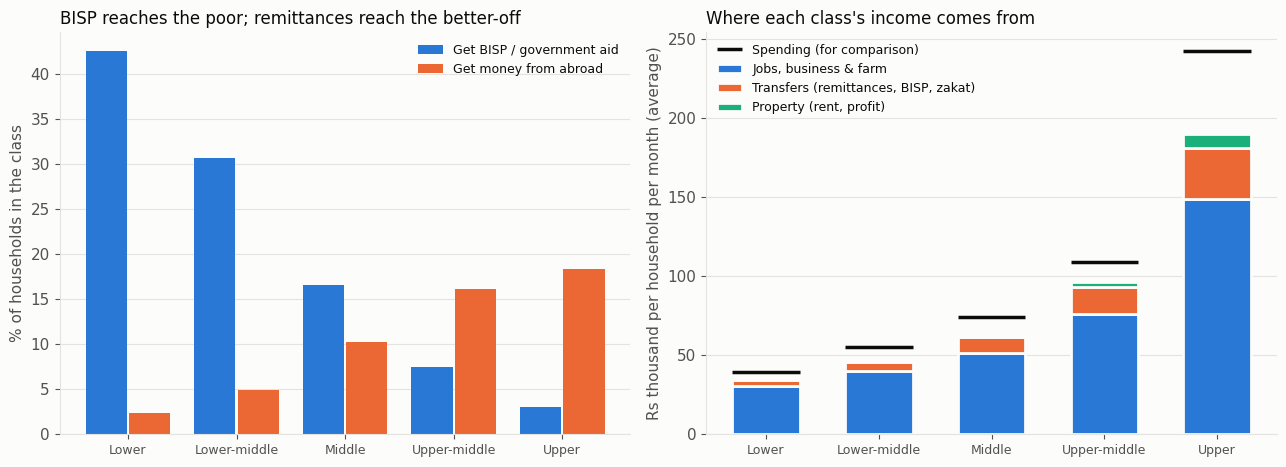

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
bw = 0.38
ax.bar(XPOS - bw / 2 - 0.01, by_class.loc["% of households getting BISP / govt aid"], bw, color=SERIES[0], label="Get BISP / government aid")
ax.bar(XPOS + bw / 2 + 0.01, by_class.loc["% of households getting remittances from abroad"], bw, color=SERIES[1], label="Get money from abroad")
ax.set_xticks(XPOS, NAMES, fontsize=9)
style(ax, "% of households in the class")
ax.set_title("BISP reaches the poor; remittances reach the better-off", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
parts = [("jobs, business & farm (Rs)", "Jobs, business & farm"),
         ("transfers (Rs)", "Transfers (remittances, BISP, zakat)"),
         ("property income (Rs)", "Property (rent, profit)")]
bottom = np.zeros(5)
for (row, label), colour in zip(parts, SERIES):
    v = by_class.loc[row].to_numpy() / 1000
    ax.bar(XPOS, v, 0.6, bottom=bottom, color=colour, label=label, edgecolor=SURFACE, linewidth=2)
    bottom += v
ax.hlines(by_class.loc["spending (Rs)"] / 1000, XPOS - 0.3, XPOS + 0.3, colors=INK, linewidth=2.5,
          label="Spending (for comparison)", zorder=3)
ax.set_xticks(XPOS, NAMES, fontsize=9)
style(ax, "Rs thousand per household per month (average)")
ax.set_title("Where each class's income comes from", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9, loc="upper left")

plt.tight_layout(); plt.savefig(OUT + "income_sources.png", dpi=150); plt.show()


### Test C: K-means on **full income** per person

Same method as Test A, using full income per person instead of spending.

A few households report almost no income: under-reporting is common in income surveys. On a log scale those values sit far away from everyone else and would capture whole clusters. So we **winsorize** before clustering: anyone below the 1st percentile (weighted) is raised to the 1st-percentile value.


In [17]:
srt = hh.sort_values("full_income_pp")
p1 = srt.full_income_pp[(srt.people_w.cumsum() / srt.people_w.sum()) >= 0.01].iloc[0]
X_income = np.log(hh[["full_income_pp"]].clip(lower=p1).to_numpy())
print(f"1st percentile of full income per person: Rs {p1:,.0f}")

hh["class_C"] = kmeans_classes(X_income, hh.people_w)
g = hh.groupby("class_C")
test_c = pd.DataFrame({
    "class": [CLASS_NAMES[k] for k in g.groups],
    "% of people (by INCOME)": g.people_w.sum() / hh.people_w.sum() * 100,
    "income per person from (Rs)": g.full_income_pp.min().round(0),
    "to": g.full_income_pp.max().round(0),
})
test_c["% of people (by SPENDING, Test A)"] = test_a["% of people"].to_numpy()
display(test_c)

agree = pd.crosstab(hh.class_A, hh.class_C, values=hh.people_w, aggfunc="sum", normalize="index") * 100
agree.index = [f"spending: {CLASS_NAMES[k]}" for k in agree.index]
agree.columns = [f"income: {CLASS_NAMES[k]}" for k in agree.columns]
display(agree.round(0))
same = (hh.people_w * (hh.class_A == hh.class_C)).sum() / hh.people_w.sum() * 100
near = (hh.people_w * ((hh.class_A - hh.class_C).abs() <= 1)).sum() / hh.people_w.sum() * 100
print(f"Same class by income and by spending: {same:.0f}% of people; same or next-door class: {near:.0f}%")


1st percentile of full income per person: Rs 1,958


,class,% of people (by INCOME),income per person from (Rs),to,"% of people (by SPENDING, Test A)"
class_C,,,,,
1,Lower,14.9,0.0,"4,512.0",16.9
2,Lower-middle,31.1,"4,512.0","7,733.0",32.6
3,Middle,30.1,"7,738.0","13,250.0",29.7
4,Upper-middle,18.5,"13,258.0","28,167.0",16.8
5,Upper,5.4,"28,182.0","702,500.0",4.0


,income: Lower,income: Lower-middle,income: Middle,income: Upper-middle,income: Upper
spending: Lower,58.0,37.0,5.0,0.0,0.0
spending: Lower-middle,12.0,59.0,26.0,3.0,0.0
spending: Middle,3.0,17.0,59.0,20.0,1.0
spending: Upper-middle,2.0,3.0,18.0,63.0,14.0
spending: Upper,2.0,2.0,6.0,21.0,68.0


Same class by income and by spending: 60% of people; same or next-door class: 96%


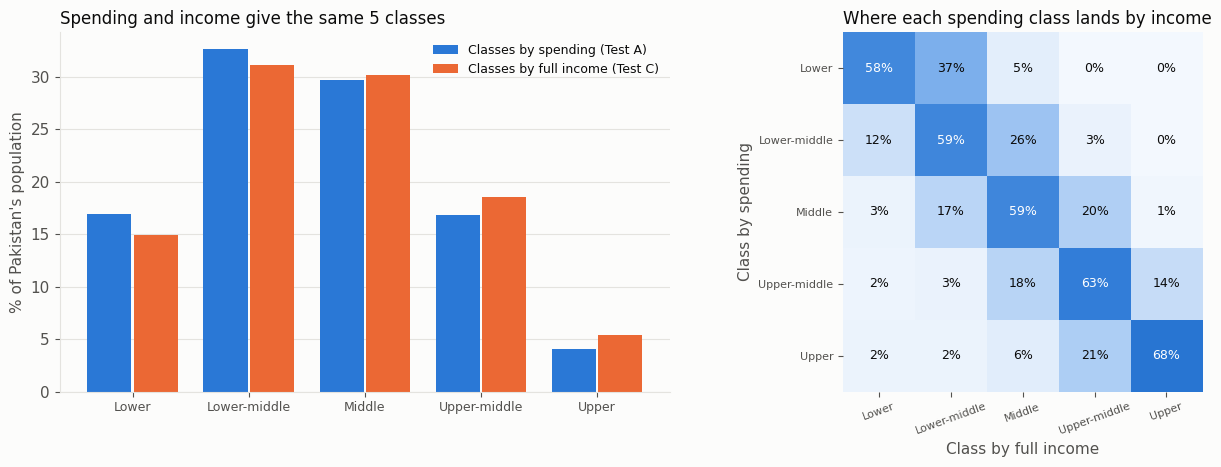

In [18]:
from matplotlib.colors import LinearSegmentedColormap
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})

ax = axes[0]
bw = 0.38
ax.bar(XPOS - bw / 2 - 0.01, test_c["% of people (by SPENDING, Test A)"], bw, color=SERIES[0], label="Classes by spending (Test A)")
ax.bar(XPOS + bw / 2 + 0.01, test_c["% of people (by INCOME)"], bw, color=SERIES[1], label="Classes by full income (Test C)")
ax.set_xticks(XPOS, NAMES, fontsize=9)
style(ax, "% of Pakistan's population")
ax.set_title("Spending and income give the same 5 classes", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
blues = LinearSegmentedColormap.from_list("blues", ["#f3f8fe", "#86b6ef", "#2a78d6", "#104281"])
m = agree.to_numpy()
ax.imshow(m, cmap=blues, vmin=0, vmax=100)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{m[i, j]:.0f}%", ha="center", va="center", fontsize=9, color="white" if m[i, j] > 45 else INK)
ax.set_xticks(range(5), NAMES, fontsize=8, rotation=20)
ax.set_yticks(range(5), NAMES, fontsize=8)
ax.set_xlabel("Class by full income")
ax.set_ylabel("Class by spending")
ax.set_title("Where each spending class lands by income", loc="left", fontsize=12)
for side in ax.spines.values(): side.set_visible(False)

plt.tight_layout(); plt.savefig(OUT + "spending_vs_income_classes.png", dpi=150); plt.show()


In [19]:
keep = ["hhcode", "prcode", "province", "region", "hhsize", "weight", "people_w",
        "monthly_total", "per_person", "income_month", "earners", "income_per_person",
        "transfers", "property_income", "full_income", "full_income_pp",
        "quintile", "class_A", "class_B", "class_C"] + CATS
saved = hh[keep].copy()
saved.insert(saved.columns.get_loc("class_A") + 1, "class_A_name", saved.class_A.map(CLASS_NAMES))
saved.insert(saved.columns.get_loc("class_C") + 1, "class_C_name", saved.class_C.map(CLASS_NAMES))
saved["province"] = saved.province.map({1: "kp", 2: "punjab", 3: "sindh", 4: "balochistan"})
saved["region"] = saved.region.map({1: "rural", 2: "urban"})
saved.round(1).to_csv(OUT + "household_classes.csv", index=False, encoding="utf-8-sig")
test_a.to_csv(OUT + "test_a_class_summary.csv", encoding="utf-8-sig")
print("Saved:", sorted(os.listdir(OUT)))


Saved: ['household_classes.csv', 'household_vs_salary.png', 'income_sources.png', 'spending_vs_income_classes.png', 'test_a_class_summary.csv', 'test_a_classes.png']


## Conclusions

### 1. Yes, weighted K-means divides the population into 5 spending classes

| Class | Spending per person per month | % of people | About how many people |
|---|---|---:|---:|
| Lower | below Rs 6,440 | 16.9% | 40.5 million |
| Lower-middle | Rs 6,440 – 10,287 | 32.6% | 78.2 million |
| Middle | Rs 10,288 – 16,882 | 29.7% | 71.2 million |
| Upper-middle | Rs 16,885 – 34,370 | 16.8% | 40.3 million |
| Upper | above Rs 34,408 | **4.0%** | **9.6 million** |

- Quintiles force 20% into every group. K-means shows that **62% of people sit in the lower-middle and middle classes**, and only **4% form a clearly separate upper class**. That 4% spends on average Rs 59,203 per person per month, more than 4 times the national average of Rs 13,608.
- The result is **stable**: different random starts give almost the same classes (adjusted Rand index 0.96-0.995).

### 2. Clustering the *pattern* of spending finds household types, not classes

Test B clustered on 12 spending categories. Only its poorest and richest clusters line up with quintiles. The middle clusters are split by **what** a household buys, not **how much**:

- in cluster 3, 98% of people live in households that spend nothing on tobacco;
- in cluster 4, 97% live in households that spend nothing on education.

So these clusters separate smokers from non-smokers and families with students from families without. For "class", use spending per person (Test A).

### 3. KNN recognises the classes from spending patterns 84% of the time

Given only the 12-category spending pattern, KNN (k = 15) predicts the Test A class correctly for **84.5% of people** (weighted, on households it never saw). Every mistake is to a **neighbouring** class. The upper class is hardest (63% correct; the rest are predicted as upper-middle), because it is small and the line between "rich" and "very rich" is blurry. This means the classes are not arbitrary cuts: households in the same class really do spend alike.

### 4. The weight: needed for correctness, though here it shifts national shares by only about 1 point

- The sample is not a copy of Pakistan. Sindh and Balochistan are **36.6% of the sample but 29.2% of the population**, and Punjab is 44.8% vs 53.8%. Only the weighted results describe Pakistan.
- For these national class shares the difference was small: no class moved by more than about 1.2 percentage points. That's because over-sampling in poorer and in richer areas partly cancels out. Do **not** assume this always happens. For provinces, rural/urban splits, or other indicators, the gap can be several points (in the guide's example, internet access in Sindh is 59.6% unweighted vs 66.7% weighted).
- The weight is also what turns shares into **people**, such as "9.6 million in the upper class".

### 5. Income (Section 1B): what a household in each class looks like

| Class | People per household | Earners | Household spending / month | Household job income / month | One worker's pay / month |
|---|---:|---:|---:|---:|---:|
| Lower | 7.7 | 1.9 | Rs 36,700 | Rs 26,800 | Rs 15,000 |
| Lower-middle | 6.7 | 1.7 | Rs 51,000 | Rs 35,300 | Rs 21,500 |
| Middle | 5.7 | 1.5 | Rs 67,400 | Rs 45,000 | Rs 30,000 |
| Upper-middle | 4.8 | 1.3 | Rs 99,900 | Rs 62,000 | Rs 45,000 |
| Upper | 4.1 | 1.2 | Rs 196,800 | Rs 100,000 | Rs 80,000 |

*(medians, weighted)*

- **Rs 34,400 is spending per person, not a salary.** A typical upper-class household spends about **Rs 197,000 a month**, and its main worker earns about **Rs 80,000**.
- **A Rs 40,000 salary is middle class at best.** One earner on Rs 40,000 supporting 6 people gives about Rs 6,700 per person, which is lower-middle. The median worker in Pakistan earns about **Rs 25,000**, and only about 28% earn Rs 40,000 or more.
- **Family size matters as much as pay.** Poorer households have almost **twice as many people** (7.7 vs 4.1) and only slightly more earners. The same salary stretches across more mouths.
- **Income and spending agree** (correlation 0.71). That's good: the spending classes are confirmed by a separate source.
- Job income is **lower than spending** in every class. That's expected: Section 1B leaves out business and farm profits, remittances, BISP and the value of owning your home. Use it to describe the classes, not to re-define them.

### 6. Full income: business, farm, transfers and property

- **Business and farm income were already counted.** Section 1B's "main job" earnings are the net income of shopkeepers, employers and farmers. For self-employed people, the profit worked out from their Section 11 business sheet is almost the same number (median ratio 1.02). Adding Sections 10/11 again would double-count it.
- **Adding transfers and property income** raises average household income from Rs 56,300 (jobs only) to **Rs 69,000** a month.
- **Who gets what:**
  - **BISP / government aid** reaches 43% of lower-class households but only 3% of upper-class ones. It is well targeted at the poor.
  - **Remittances from abroad** go the other way: 2% of lower-class households receive them vs 18% of upper-class ones. Having a family member abroad is part of what puts a family higher up.
- **Classes by income look almost exactly like classes by spending:**

| Class | % of people by income (Test C) | % of people by spending (Test A) |
|---|---:|---:|
| Lower | 14.9% | 16.9% |
| Lower-middle | 31.1% | 32.6% |
| Middle | 30.1% | 29.7% |
| Upper-middle | 18.5% | 16.8% |
| Upper | 5.4% | 4.0% |

  60% of people land in the **same** class either way, and **96%** land in the same or a neighbouring class. Two independent measures give the same picture of society, which makes the 5-class result much more convincing.
- Reported income (Rs 69,000) is still **below** spending (Rs 81,400). This is normal in household surveys: people under-report income, and spending includes things like the value of living in your own house. That is why PBS, and this notebook, rank households by **spending**.

### Limitations, before anyone quotes these numbers

- **One peak, not five groups.** Spending per person has a single hump (see the chart), so there are no "natural gaps" between classes. K-means picks the cut points that make each class as tight as possible. The classes are a sensible split, not something hidden in the data.
- **Spending is not wealth or income.** A household that bought a car or gold this year looks richer for one year.
- **No price adjustment.** Rs 10,000 buys more in a village than in Karachi or Lahore, and children are counted the same as adults. PBS's official method may adjust for these; see Appendix A of the report.
- **Part D recorded totals** disagree with their items for about 18% of households. We used the items.
